# Curso: Data Mining — Semana 10 - Lunes
## <font color=green>Laboratorio: Distancias, escalamiento y K-means</font>

**Docente:** Soledad Espezúa Llerena


## <font color=green>Objetivos</font>

1. Comprobar cómo la escala modifica la noción de cercanía entre registros.
2. Conectar la distancia euclidiana con el funcionamiento de K-means.
3. Elegir un valor **tentativo** de $K$ usando la inercia y el método del codo.
4. Interpretar los grupos obtenidos en las unidades originales.

> La evaluación con **Silhouette** y **Davies-Bouldin** se realizará en la siguiente sesión de evaluación de clustering.


## <font color=F54927>Recordatorio: semana 9 → semana 10</font>

En la sesión anterior trabajamos con dos situaciones diferentes:

- **Selección supervisada de atributos:** en ejemplos con `f_classif`, `chi2`, RFE/SFS y modelos embedded utilizamos una variable objetivo real `y`.
- **PCA y NMF:** transforman la representación de los datos usando solamente `X`; no necesitan una clase conocida.

Ahora, en clustering:

X → algoritmo de clustering → etiqueta de cluster

La etiqueta obtenida (`0`, `1`, `2`, ...) **no es una clase verdadera**. Es un resultado del algoritmo y depende de las variables, el preprocesamiento, la distancia y el método utilizados.

Después podremos usar esas etiquetas para **perfilar e interpretar** los grupos.


In [1]:
# Librerías
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# <font color=blue>PARTE I. ¿Qué significa que dos registros sean “cercanos”?</font>

Usaremos un ejemplo pequeño para observar qué ocurre cuando dos variables tienen **unidades y escalas diferentes**.

En esta primera parte utilizaremos **MinMaxScaler** para que la transformación sea fácil de interpretar: cada atributo quedará entre 0 y 1.

> **Importante:** antes de escalar datos reales se deben revisar los outliers. El escalamiento cambia la escala, pero **no corrige** valores atípicos.


In [2]:
# Seis clientes ficticios.
# Evitamos introducir un outlier extremo porque aquí queremos estudiar
# únicamente el efecto de la ESCALA de las variables.

df_clientes = pd.DataFrame({
    "edad": [22, 25, 30, 28, 45, 35],               # años
    "gasto_mensual": [200, 300, 350, 500, 800, 450] # soles
}, index=["C1", "C2", "C3", "C4", "C5", "C6"])

display(df_clientes)


,edad,gasto_mensual
C1,22,200
C2,25,300
C3,30,350
C4,28,500
C5,45,800
C6,35,450


## <font color=green>1. Distancia euclidiana sin escalar</font>

La distancia euclidiana representa la distancia en línea recta.

Cuando una variable tiene valores numéricamente mucho mayores que otra, puede dominar el cálculo de la distancia **solo por su escala**.


In [3]:
# Calculamos todas las distancias euclidianas entre pares de clientes
# usando directamente las unidades originales.

D_raw = squareform(
    pdist(df_clientes.values, metric="euclidean")
)

D_raw = pd.DataFrame(
    D_raw,
    index=df_clientes.index,
    columns=df_clientes.index
)

display(D_raw.round(2))


,C1,C2,C3,C4,C5,C6
C1,0.00,100.04,150.21,300.06,600.44,250.34
C2,100.04,0.00,50.25,200.02,500.40,150.33
C3,150.21,50.25,0.00,150.01,450.25,100.12
C4,300.06,200.02,150.01,0.00,300.48,50.49
C5,600.44,500.40,450.25,300.48,0.00,350.14
C6,250.34,150.33,100.12,50.49,350.14,0.00


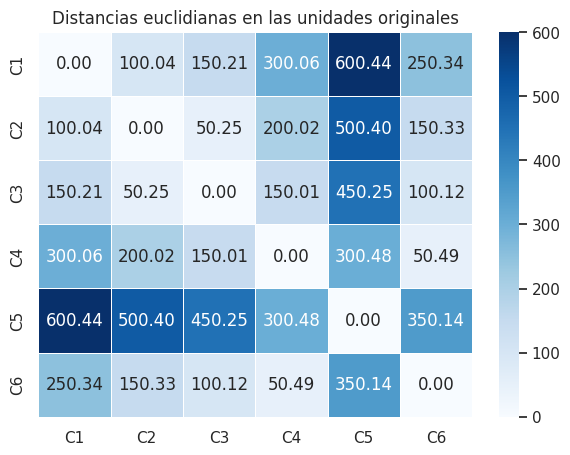

In [17]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    D_raw,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Distancias euclidianas en las unidades originales")
plt.show()


### Observa

`gasto_mensual` está medido en centenas de soles, mientras que `edad` está alrededor de decenas de años.

Por ello, gran parte de la distancia queda determinada por las diferencias en gasto.

Esto **no significa que siempre debamos escalar**. La pregunta metodológica es:

> ¿Queremos que las unidades originales determinen cuánto pesa cada atributo en la distancia?


## <font color=green>2. Distancia después de escalar con Min-Max</font>

`MinMaxScaler` transforma cada atributo, normalmente, al intervalo \([0,1]\):

Así evitamos que una variable domine únicamente porque sus valores están expresados en una escala numérica mayor.


In [5]:
# Escalamos cada atributo al intervalo [0, 1].
scaler_demo = MinMaxScaler()

X_demo_mm = scaler_demo.fit_transform(df_clientes)

df_demo_mm = pd.DataFrame(
    X_demo_mm,
    index=df_clientes.index,
    columns=["edad_minmax", "gasto_minmax"]
)

display(df_demo_mm.round(3))


,edad_minmax,gasto_minmax
C1,0.000,0.000
C2,0.130,0.167
C3,0.348,0.250
C4,0.261,0.500
C5,1.000,1.000
C6,0.565,0.417


In [6]:
# Volvemos a calcular las distancias, pero ahora en el espacio escalado.

D_mm = squareform(
    pdist(X_demo_mm, metric="euclidean")
)

D_mm = pd.DataFrame(
    D_mm,
    index=df_clientes.index,
    columns=df_clientes.index
)

display(D_mm.round(3))


,C1,C2,C3,C4,C5,C6
C1,0.000,0.212,0.428,0.564,1.414,0.702
C2,0.212,0.000,0.233,0.358,1.204,0.502
C3,0.428,0.233,0.000,0.265,0.994,0.274
C4,0.564,0.358,0.265,0.000,0.892,0.316
C5,1.414,1.204,0.994,0.892,0.000,0.728
C6,0.702,0.502,0.274,0.316,0.728,0.000


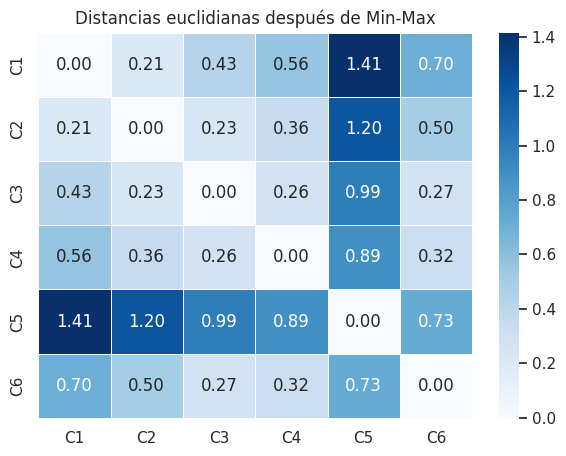

In [16]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    D_mm,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Distancias euclidianas después de Min-Max")
plt.show()


### Discute

1. ¿Cambió quién está cerca de quién?
2. ¿Por qué cambió la matriz de distancias?
3. ¿Qué decisión metodológica estamos tomando al escalar?
4. ¿Qué podría ocurrir si existiera un outlier extremo antes de aplicar Min-Max?

> **Importante:** `StandardScaler` también es una alternativa. Puede generar valores negativos porque un z-score negativo significa simplemente **“por debajo de la media”**. Eso no representa un problema para la distancia euclidiana ni para K-means.


## <font color=green>3. Euclidiana y Manhattan</font>

- **Euclidiana:** mide la distancia en línea recta.
- **Manhattan:** suma las diferencias absolutas por atributo.

No existe una métrica universalmente mejor: la elección depende de cómo representamos los datos y de qué significa “cercanía” en el problema.


In [10]:
# Ejemplo con tres atributos numéricos.
df_estudiantes = pd.DataFrame({
    "horas_estudio": [2, 4, 6, 8, 10, 3, 7],
    "horas_sueno":   [9, 8, 7, 6, 5, 7, 8],
    "promedio":      [12, 14, 16, 17, 18, 11, 15]
}, index=["E1", "E2", "E3", "E4", "E5", "E6", "E7"])

# Distancia euclidiana.
D_euc = squareform(pdist(df_estudiantes, metric="euclidean"))

# Distancia Manhattan (cityblock en scipy).
D_man = squareform(pdist(df_estudiantes, metric="cityblock"))

print("Distancia euclidiana")
display(
    pd.DataFrame(
        D_euc,
        index=df_estudiantes.index,
        columns=df_estudiantes.index
    ).round(2)
)

print("Distancia Manhattan")
display(
    pd.DataFrame(
        D_man,
        index=df_estudiantes.index,
        columns=df_estudiantes.index
    ).round(2)
)


Distancia euclidiana


,E1,E2,E3,E4,E5,E6,E7
E1,0.00,3.00,6.00,8.37,10.77,2.45,5.92
E2,3.00,0.00,3.00,5.39,7.81,3.32,3.16
E3,6.00,3.00,0.00,2.45,4.90,5.83,1.73
E4,8.37,5.39,2.45,0.00,2.45,7.87,3.00
E5,10.77,7.81,4.90,2.45,0.00,10.10,5.20
E6,2.45,3.32,5.83,7.87,10.10,0.00,5.74
E7,5.92,3.16,1.73,3.00,5.20,5.74,0.00


Distancia Manhattan


,E1,E2,E3,E4,E5,E6,E7
E1,0.0,5.0,10.0,14.0,18.0,4.0,9.0
E2,5.0,0.0,5.0,9.0,13.0,5.0,4.0
E3,10.0,5.0,0.0,4.0,8.0,8.0,3.0
E4,14.0,9.0,4.0,0.0,4.0,12.0,5.0
E5,18.0,13.0,8.0,4.0,0.0,16.0,9.0
E6,4.0,5.0,8.0,12.0,16.0,0.0,9.0
E7,9.0,4.0,3.0,5.0,9.0,9.0,0.0


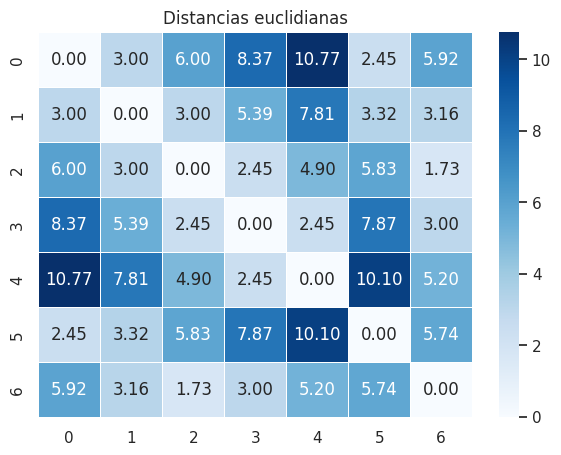

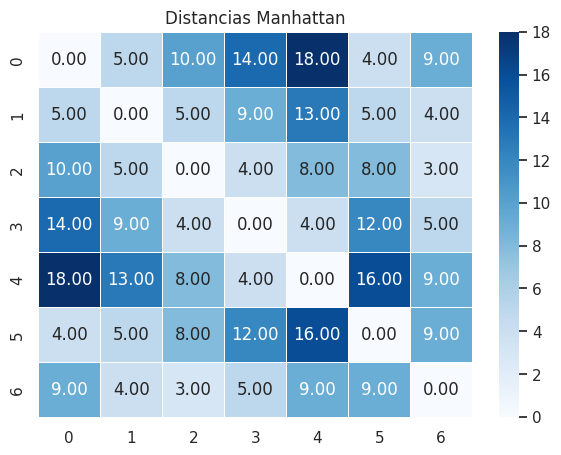

In [15]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    D_euc,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Distancias euclidianas")
plt.show()

plt.figure(figsize=(7, 5))

sns.heatmap(
    D_man,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Distancias Manhattan")
plt.show()


### Otras métricas que conviene reconocer

| Situación | Métrica |
|---|---|
| Variables binarias o categóricas alineadas | Hamming |
| Coordenadas geográficas (latitud-longitud) | Haversine |
| Variables numéricas correlacionadas | Mahalanobis |

En este laboratorio no las implementaremos todavía. Para **K-means** trabajaremos con distancia euclidiana.


# <font color=blue>PARTE II. K-means: la distancia convertida en grupos</font>

Usaremos un conjunto de datos de usuarios y rasgos de personalidad.

El algoritmo **no utilizará** `usuario` ni `categoria` para formar los clusters.

* La columna `categoria` se conservará únicamente como información externa para interpretar posteriormente la composición de los grupos.
* `wordcount` = cantidad promedio de palabras utilizadas por el usuario en sus tweets.
* `categoria` = actividad laboral/profesional del usuario, codificada numéricamente.
| `categoria` | Actividad |
|---:|---|
| 1 | Actor / actriz |
| 2 | Cantante |
| 3 | Modelo |
| 4 | TV / series |
| 5 | Radio |
| 6 | Tecnología |
| 7 | Deportes |
| 8 | Política |
| 9 | Escritor |

| Letra | Rasgo | ¿Qué mide? |
|---|---|---|
| **O** | **Openness** *(Apertura a la experiencia)* | Curiosidad intelectual, imaginación y gusto por la variedad. |
| **C** | **Conscientiousness** *(Responsabilidad / Tesón)* | Autodisciplina, organización y orientación al logro. |
| **E** | **Extraversion** *(Extraversión)* | Sociabilidad, asertividad y de dónde obtienes tu energía. |
| **A** | **Agreeableness** *(Amabilidad / Afabilidad)* | Compasión, cooperación y confianza hacia los demás. |
| **N** | **Neuroticism** *(Neuroticismo)* | Estabilidad emocional y tendencia a la ansiedad o el estrés. |


In [19]:
# Carga de datos.
df = pd.read_csv("TheBigFive.csv")

display(df.head())
print("Dimensión:", df.shape)

,usuario,op,co,ex,ag,ne,wordcount,categoria
0,3gerardpique,34.297953,28.148819,41.948819,29.370315,9.841575,37.0945,7
1,aguerosergiokun,44.986842,20.525865,37.938947,24.279098,10.362406,78.7970,7
2,albertochicote,41.733854,13.745417,38.999896,34.645521,8.836979,49.2604,4
3,AlejandroSanz,40.377154,15.377462,52.337538,31.082154,5.032231,80.4538,2
4,alfredocasero1,36.664677,19.642258,48.530806,31.138871,7.305968,47.0645,4


Dimensión: (140, 8)


In [23]:
# Variables que participarán en el clustering.
# Excluimos identificadores y la categoría externa.

features = ["op", "co", "ex", "ag", "ne", "wordcount"]

X = df[features].copy()

display(X.describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
op,140.0,44.41,8.43,30.02,38.21,44.51,49.37,71.70
co,140.0,22.98,5.82,7.85,19.74,22.47,26.09,49.64
ex,140.0,40.76,7.19,18.69,36.10,41.46,45.20,59.82
ag,140.0,22.92,7.66,9.31,17.05,21.38,28.68,40.58
ne,140.0,8.00,3.04,1.03,6.09,7.84,9.76,23.98
wordcount,140.0,98.72,44.71,5.02,66.22,94.71,119.71,217.18


## <font color=green>4. Revisamos antes de escalar</font>

Antes de aplicar K-means conviene comprobar:

- si las variables realmente deben participar en la noción de similitud;
- si existen escalas muy diferentes;
- si hay valores atípicos que deban revisarse.

**Escalar no equivale a corregir outliers.** Si un valor atípico es un error o no representa el fenómeno de interés, debe tratarse antes y con una justificación.


`melt()` reorganiza los datos de formato ancho a formato largo: convierte los nombres de las columnas en una columna llamada **atributo** y apila sus valores en otra llamada **valor**.
Esto facilita, por ejemplo, graficar un boxplot para cada atributo en una sola instrucció

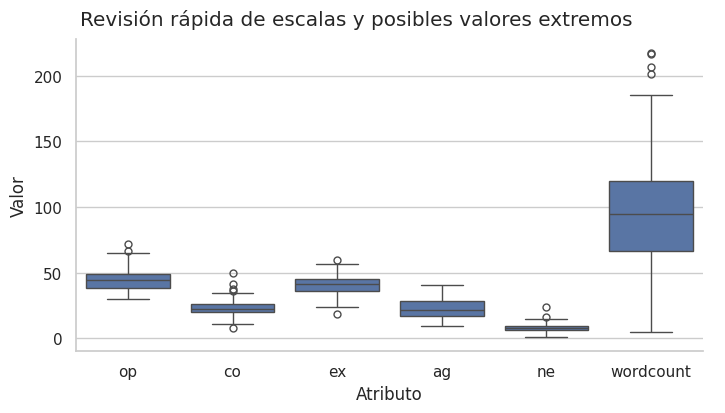

In [22]:
# Reorganizamos los datos de formato ancho a formato largo.
# Los nombres de las columnas pasan a la columna "atributo"
# y sus valores se apilan en la columna "valor".
X_long = X.melt(
    var_name="atributo",
    value_name="valor"
)

# Dibujamos un boxplot para cada atributo.
# Esto permite comparar sus escalas y detectar posibles valores extremos.
g = sns.catplot(
    data=X_long,
    x="atributo",
    y="valor",
    kind="box",
    height=4,
    aspect=1.8
)

g.set_axis_labels("Atributo", "Valor")
g.fig.suptitle("Revisión rápida de escalas y posibles valores extremos", y=1.03)
plt.show()


`wordcount` tiene una escala distinta de los rasgos OCEAN, conviene escalarla antes de K-means

## <font color=green>5. Escalamiento antes de K-means</font>

K-means asigna cada observación al centroide más cercano utilizando distancia euclidiana.

En este caso utilizaremos `StandardScaler` para expresar cada atributo en unidades comparables.

> Los valores negativos que aparezcan son **z-scores negativos**: indican que la observación está por debajo de la media del atributo. Son perfectamente válidos para K-means.


In [51]:
# Creamos el objeto StandardScaler para estandarizar
# cada atributo numérico.
scaler = StandardScaler()

# Calculamos la media y desviación estándar de cada atributo
# y transformamos los datos a z-scores.
# Cada variable queda aproximadamente con media 0 y desviación estándar 1.
X_std = scaler.fit_transform(X)

# StandardScaler devuelve un array de NumPy.
# Lo convertimos nuevamente en DataFrame para recuperar
# los nombres de las variables y los índices originales.
X_std_df = pd.DataFrame(
    X_std,
    columns=features,
    index=df.index
)

display(X_std_df.describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
op,140.0,0.0,1.0,-1.71,-0.74,0.01,0.59,3.25
co,140.0,-0.0,1.0,-2.61,-0.56,-0.09,0.54,4.60
ex,140.0,-0.0,1.0,-3.08,-0.65,0.10,0.62,2.66
ag,140.0,-0.0,1.0,-1.78,-0.77,-0.20,0.75,2.32
ne,140.0,-0.0,1.0,-2.30,-0.63,-0.05,0.58,5.28
wordcount,140.0,-0.0,1.0,-2.10,-0.73,-0.09,0.47,2.66


In [52]:
X_std_df.head()

,op,co,ex,ag,ne,wordcount
0,-1.204996,0.892279,0.165428,0.845612,0.608075,-1.383060
1,0.068161,-0.422922,-0.394646,0.178325,0.780058,-0.447063
2,-0.319303,-1.592763,-0.246459,1.537014,0.276347,-1.110001
3,-0.480900,-1.311184,1.616460,1.069976,-0.980020,-0.409877
4,-0.923095,-0.575372,1.084760,1.077410,-0.229209,-1.159287


## <font color=green>6. Elegimos un $K$ tentativo con la inercia</font>

Por ahora utilizaremos solamente la **inercia**, que es la función objetivo propia de K-means.

La inercia disminuye al aumentar \(K\), por lo que no elegimos simplemente el valor que produzca la menor inercia.

Buscamos un punto donde agregar nuevos clusters empiece a producir una reducción cada vez menor: el **método del codo**.

> La próxima semana complementaremos esta decisión con **Silhouette** y **Davies-Bouldin**.


In [32]:
# Lista donde guardaremos el número de clusters (k)
# y la inercia obtenida para cada solución.
resultados_k = []

# Probamos diferentes números de clusters.
# Como ahora solo necesitamos la inercia, podemos comenzar con K=1.
for k in range(1, 8):

    modelo = KMeans(
        n_clusters=k,        # número de clusters que queremos formar
        init="k-means++",    # inicialización de centroides bien separados
        n_init=10,           # ejecuta K-means 10 veces y conserva la mejor solución
        random_state=42      # permite reproducir los resultados
    )

    # Ajustamos K-means sobre los datos estandarizados.
    modelo.fit(X_std)

    # Guardamos el valor de k y la inercia obtenida.
    # La inercia es la suma de las distancias al cuadrado
    # de cada observación a su centroide asignado.
    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_
    })

resultados_k = pd.DataFrame(resultados_k)

display(resultados_k.round(2))

,k,inercia
0,1,840.00
1,2,565.40
2,3,478.52
3,4,430.68
4,5,393.46
5,6,365.25
6,7,337.49


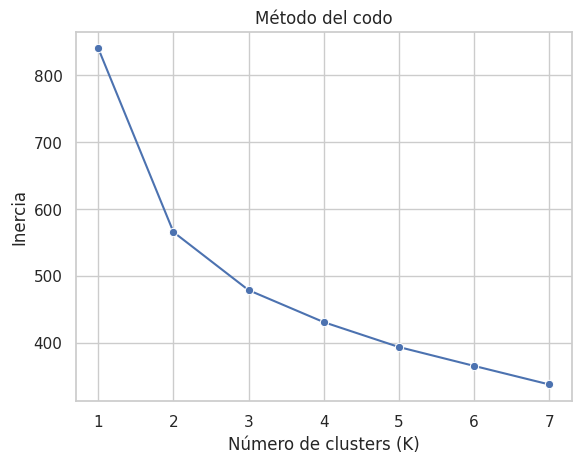

In [45]:
ax = sns.lineplot(
    data=resultados_k,
    x="k",
    y="inercia",
    marker="o"
)

ax.set(
    title="Método del codo",
    xlabel="Número de clusters (K)",
    ylabel="Inercia"
)

plt.show()

#### <font color=966129>Decisión tentativa</font>

La decisión de hoy es **tentativa** porque se basa en la inercia y en la posibilidad de interpretar los grupos.

En la siguiente sesión volveremos sobre esta solución incorporando otras métricas internas.


In [47]:
# Para continuar el ejemplo utilizaremos K=2.
# Si durante la discusión se propone otro valor razonable,
# puede modificarse y volver a ejecutar las celdas siguientes.

k_elegido = 2

kmeans = KMeans(
    n_clusters=k_elegido,
    init="k-means++",
    n_init=10,
    random_state=42
)

# Ajustamos K-means y, al mismo tiempo, obtenemos
# la etiqueta de cluster asignada a cada observación.
df["cluster_kmeans"] = kmeans.fit_predict(X_std)

# Mostramos la inercia de la solución final.
# Una menor inercia indica que, en promedio,
# las observaciones están más próximas a sus centroides.
print("Inercia:", round(kmeans.inertia_, 2))

# Contamos cuántas observaciones quedaron asignadas
# a cada cluster y ordenamos los resultados por etiqueta.
print("\nTamaño de los clusters:")
display(df["cluster_kmeans"].value_counts().sort_index())

Inercia: 565.4

Tamaño de los clusters:


,count
cluster_kmeans,
0,88
1,52


## <font color=green>7. Visualizamos la solución con PCA</font>

PCA se utilizará **solo para visualizar** los clusters en dos dimensiones.

K-means ya fue entrenado utilizando las seis variables estandarizadas.


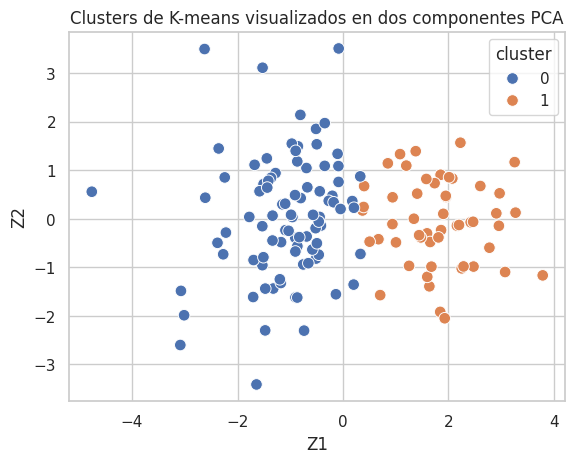

Varianza representada en el plano: 65.1 %


In [56]:
# Creamos una representación en 2 dimensiones usando PCA.
# PCA se usa aquí únicamente para visualizar los clusters,
# no para volver a entrenar K-means.
pca = PCA(n_components=2)

# Proyectamos los datos estandarizados sobre las dos
# primeras componentes principales.
Z = pca.fit_transform(X_std)

viz = pd.DataFrame({
    "Z1": Z[:, 0],  # coordenada en la primera componente principal
    "Z2": Z[:, 1],  # coordenada en la segunda componente principal

    # Agregamos la etiqueta obtenida previamente con K-means
    # solo para colorear e interpretar los grupos en el gráfico.
    "cluster": df["cluster_kmeans"].astype(str)
})

'''
NOTA: astype(str) convierte las etiquetas numéricas de los clusters
en categorías de texto para que Seaborn las trate como grupos discretos
al asignar los colores.
# Porque 0, 1 y 2 son nombres de grupos y no valores numéricos ordenados.
'''

# Graficamos cada observación en el espacio reducido de PCA.
# Z1 y Z2 corresponden a las dos primeras componentes principales.
# El color de cada punto representa el cluster asignado por K-means.
ax = sns.scatterplot(
    data=viz,
    x="Z1",           # eje horizontal: primera componente principal
    y="Z2",           # eje vertical: segunda componente principal
    hue="cluster",    # colorea los puntos según el cluster
    s=70              # tamaño de los puntos
)

ax.set(title="Clusters de K-means visualizados en dos componentes PCA")

plt.show()

print("Varianza representada en el plano:",
    round(pca.explained_variance_ratio_.sum() * 100, 1),
    "%")


## <font color=green>8. Perfilamos los clusters en las unidades originales</font>

El algoritmo trabajó con datos estandarizados, pero para **interpretar** los grupos conviene volver a las unidades originales.

La etiqueta `cluster_kmeans` no tiene significado por sí sola. Debemos estudiar qué caracteriza a cada grupo.


In [63]:
# Calculamos el promedio de cada variable ORIGINAL dentro de cada cluster.
# Esto permite describir e interpretar qué caracteriza a cada grupo.
perfil = (
    df.groupby("cluster_kmeans")[features]  # agrupamos las observaciones según su cluster
      .mean()                              # calculamos el promedio de cada atributo
      .round(2)                            # redondeamos a 2 decimales
)

# Calculamos cuántas observaciones contiene cada cluster.
tamanos = (
    df.groupby("cluster_kmeans")
      .size()                              # número de observaciones por cluster
      .rename("n")                         # llamamos "n" a esta nueva columna
)

# Agregamos el tamaño de cada cluster a la tabla de perfilamiento.
perfil = perfil.join(tamanos)

# Mostramos la tabla final.
display(perfil)


,op,co,ex,ag,ne,wordcount,n
cluster_kmeans,,,,,,,
0,48.46,25.10,37.37,18.42,8.32,119.14,88
1,37.56,19.39,46.50,30.52,7.46,64.15,52


Convertimos los promedios de cada cluster a z-scores para comparar fácilmente qué atributos están por encima o por debajo de la media general.

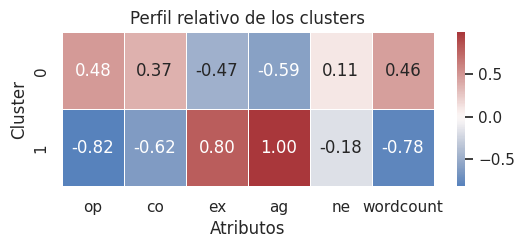

In [62]:
# Para visualizar el perfil relativo, expresamos los promedios de cada cluster
# en unidades estandarizadas respecto a la distribución original.
# Esto NO cambia la tabla anterior: solo facilita la comparación visual.

perfil_z = perfil[features].copy()

# Estandarizamos los promedios de cada cluster usando
# la media y desviación estándar de los datos originales.
# Así podemos comparar en una misma escala qué tan por encima
# o por debajo de la media general se encuentra cada cluster.
perfil_z = ( perfil_z - X.mean()) / X.std(ddof=0)

plt.figure(figsize=(6, 2))

sns.heatmap(
    perfil_z,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="vlag",
    linewidths=0.5
)

plt.title("Perfil relativo de los clusters")
plt.xlabel("Atributos")
plt.ylabel("Cluster")
plt.show()


### Preguntas de interpretación

1. ¿Qué atributos parecen diferenciar más a los clusters?

Los que muestran mayores diferencias entre ambos grupos son Agreeableness (ag), Openness (op), Extraversion (ex) y wordcount. Conscientiousness (co) también diferencia, aunque algo menos. Neuroticism (ne) cambia poco entre los clusters, por lo que no parece ser un atributo importante para diferenciarlos.

2. ¿Qué nombre **descriptivo** —no una etiqueta verdadera— pondrías a cada grupo?
- Cluster 0: “Abiertos y reservados”: presentan mayor apertura (op), mayor responsabilidad (co) y mayor wordcount, pero menor extraversión (ex) y amabilidad (ag).
- Cluster 1: “Sociables y afables”: destacan por alta extraversión y amabilidad, pero presentan menor apertura, responsabilidad y wordcount.

3. ¿La **`categoría`** externa se concentra en algún cluster?

In [64]:
# La categoría NO participó en el clustering.
# La usamos únicamente para interpretar la composición posterior de los grupos.

tabla_categoria = pd.crosstab(
    df["cluster_kmeans"],
    df["categoria"],
    normalize="index"
).round(2)

display(tabla_categoria)


categoria,1,2,3,4,5,6,7,8,9
cluster_kmeans,,,,,,,,,
0,0.25,0.30,0.1,0.07,0.01,0.05,0.09,0.11,0.02
1,0.10,0.15,0.0,0.25,0.06,0.08,0.17,0.12,0.08


Algunas categorías profesionales aparecen con mayor frecuencia en determinado cluster.

# <font color=blue>DESAFÍO GRUPAL — Avance del proyecto</font>

Trabajen con la **matriz analítica de su proyecto**.

### <font color=green>A. Preparación</font>

1. Definan claramente la **unidad de análisis**.
2. Seleccionen las variables numéricas que realmente deberían participar en la noción de similitud entre observaciones.
3. Excluyan identificadores, códigos y variables que no deberían intervenir en la distancia.
4. Revisen escalas y posibles outliers antes de escalar.
5. Justifiquen el escalamiento elegido.

> Si su proyecto posee una clase externa real, **no la utilicen para formar los clusters**. Pueden conservarla para interpretar posteriormente los grupos.

### <font color=green>B. K-means</font>

6. Evalúen al menos `K = 1, 2, 3, 4, 5, 6`.
7. Presenten el gráfico de **inercia vs. K**.
8. Propongan un `K` tentativo mediante el **método del codo**.
9. Apliquen K-means con ese valor y reporten el tamaño de cada cluster.
10. Perfilen los clusters usando las variables en sus **unidades originales**.

### <font color=green>C. Producto para el proyecto</font>

- Agreguen una columna `cluster_kmeans` a su matriz analítica.
- Presenten el gráfico del codo.
- Incluyan una tabla de perfilamiento.
- Escriban una conclusión de máximo **6 líneas** explicando qué caracteriza a cada grupo y qué limitaciones tiene todavía la solución.

> **No consideren todavía esta solución como definitiva:** en la siguiente sesión la reevaluaremos con Silhouette y Davies-Bouldin.
